## 1. Imports and paths

In [12]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.api.types import is_numeric_dtype
import seaborn as sns

In [2]:
PROJECT_ROOT = Path.cwd()
TRAIN_PATH = PROJECT_ROOT / "train.csv"
TEST_PATH = PROJECT_ROOT / "test.csv"

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/apple/Documents/modules/CS5228/cs-5228-2610-project


## 2. Load the main data

Load train and test files, and use statistics and visualization for the very first analysis of data. There are no missing values in the data as seen on the Kaggle data summary.


In [3]:
train = pd.read_csv(TRAIN_PATH, dtype={"BLOCK": "string"})
test = pd.read_csv(TEST_PATH, dtype={"BLOCK": "string"})

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
print("\nMain columns:", list(train.columns))

Train shape: (150000, 11)
Test shape:  (50000, 10)

Main columns: ['RENT_APPROVAL_DATE', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL', 'FLOOR_AREA_SQM', 'FURNISHED', 'LEASE_COMMENCE_DATE', 'FEE', 'MONTHLY_RENT']


In [7]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RENT_APPROVAL_DATE,150000,51,2021-03,3705,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TOWN,150000,26,jurong west,10482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BLOCK,150000,2720,2,921,NaN,NaN,NaN,NaN,NaN,NaN,NaN
STREET,150000,1146,ang mo kio avenue 3,1590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAT_TYPE,150000,11,4-room,40688,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLAT_MODEL,150000,20,improved,44008,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FLOOR_AREA_SQM,150000.0,NaN,NaN,NaN,93.338847,24.271768,31.0,68.0,92.0,110.0,215.0
FURNISHED,150000,1,yes,150000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LEASE_COMMENCE_DATE,150000.0,NaN,NaN,NaN,1990.907473,12.64154,1966.0,1981.0,1988.0,2001.0,2022.0
FEE,150000.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 2.1 Understanding each feature

1. Rent approval date: Year and Month when the rent was approved as string, e.g., "2021-01" representing January 2021.

<Axes: xlabel='count', ylabel='RENT_APPROVAL_DATE'>

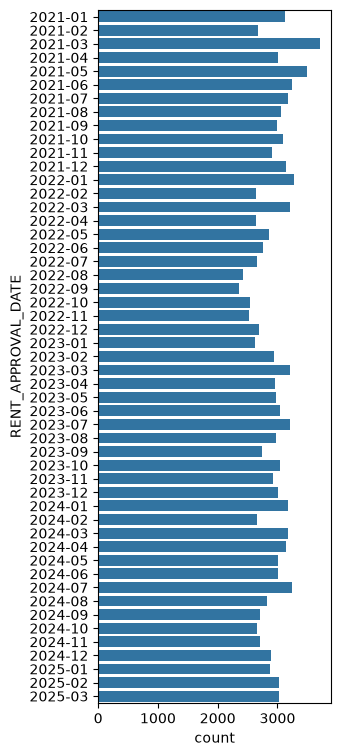

In [20]:
rent_approval = train["RENT_APPROVAL_DATE"]
plt.figure(figsize=(3, 9))
sns.countplot(data=rent_approval)

2. TOWN: The town of the sold HDB flat (e.g., "Bishan", "Queenstown", "Clementi"). From the plots, some towns have very cheap rental options, some have premium ones, while most flats are in the middle range.

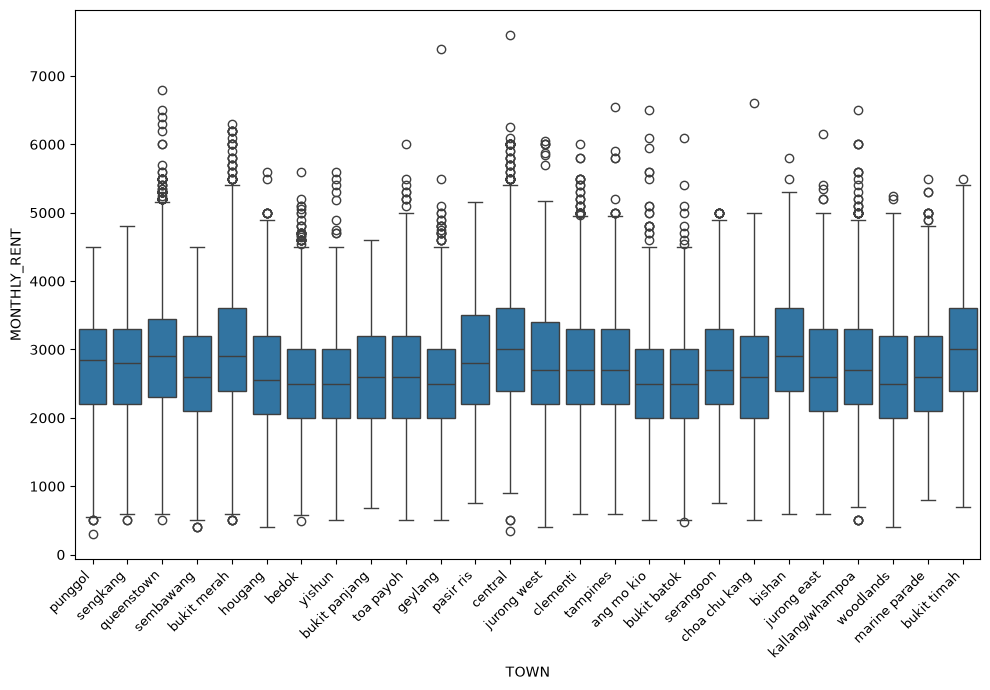

In [24]:
town = train["TOWN"]
plt.figure(figsize=(10, 7))
sns.boxplot(data=train, x="TOWN", y="MONTHLY_RENT")
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()

3. BLOCK: block number of the flat (e.g., "300", "306A", "254"). This, by itself, is intuitively a weak indicator of rent. It has many unique values, but not much use on its own. It is not possible to plot this as a count plot or box-scatter plot due to high cardinality. NOTE: We can consider removing this in the final model.

4. STREET: Street name of block containing the flat (e.g., "ubi avenue 1", "woodlands drive 14"). This also contains many unique values, so difficult to plot. It can be a good indicator combined with town and block.

5. FLAT_TYPE: type of flat (e.g., "2 room", "3 room", "4-room"). This should be related to the size of the flat, so we can plot and find any outliers/anomalies. 

Pre-processing: Normalize the categories so that '4 room' and '4-room' is the same category.
Observations: There's no visibly weird data. The room size increases from 1-room to 2,3,4,5 and then executive, which is expected.

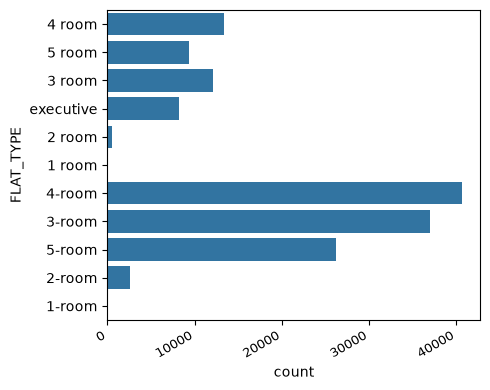

In [36]:
flat_type = train["FLAT_TYPE"]
plt.figure(figsize=(5, 4))
sns.countplot(data=flat_type)
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()

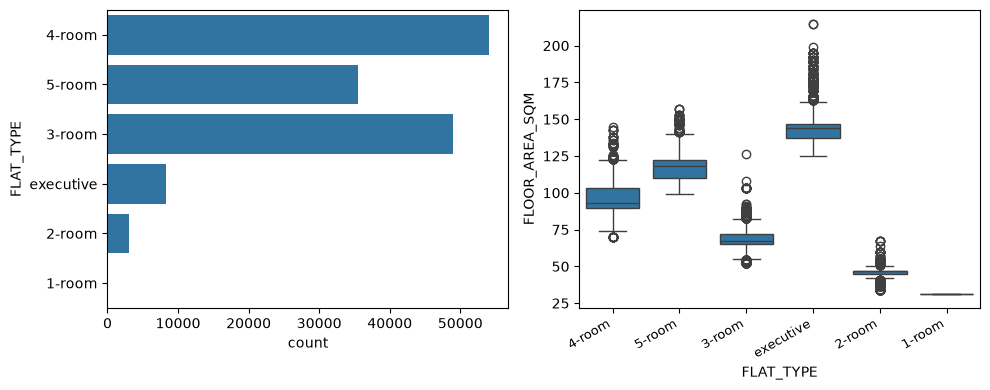

In [38]:
train["FLAT_TYPE"] = (
    train["FLAT_TYPE"].astype("string").str.lower()
    .str.replace(r"[\s-]+", "-", regex=True).str.strip()
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=train["FLAT_TYPE"], ax=axes[0])
sns.boxplot(data=train, x="FLAT_TYPE", y="FLOOR_AREA_SQM", ax=axes[1])
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()

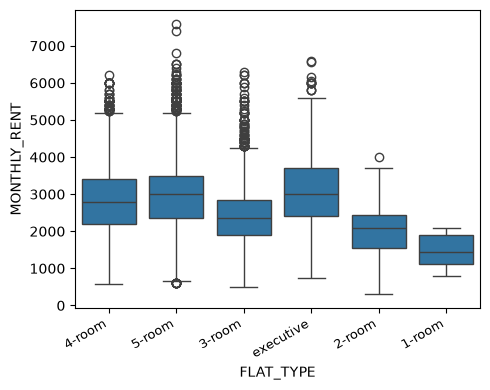

In [39]:
plt.figure(figsize=(5, 4))
sns.boxplot(data=train, x="FLAT_TYPE", y="MONTHLY_RENT")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()

6. FLAT_MODEL - model of the flat (e.g., "model a", "dbss", ''executive"). This contains 20 unique values and might be a strong predictor of the rent.

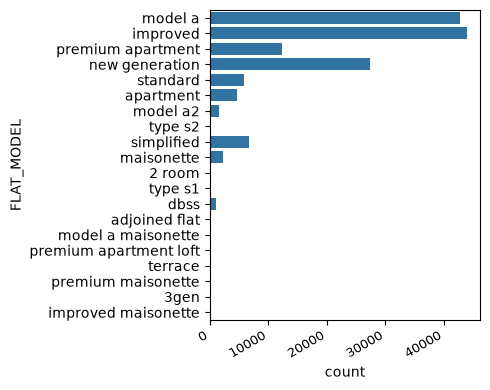

In [40]:
flat_model = train["FLAT_MODEL"]
plt.figure(figsize=(5, 4))
sns.countplot(data=flat_model)
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()

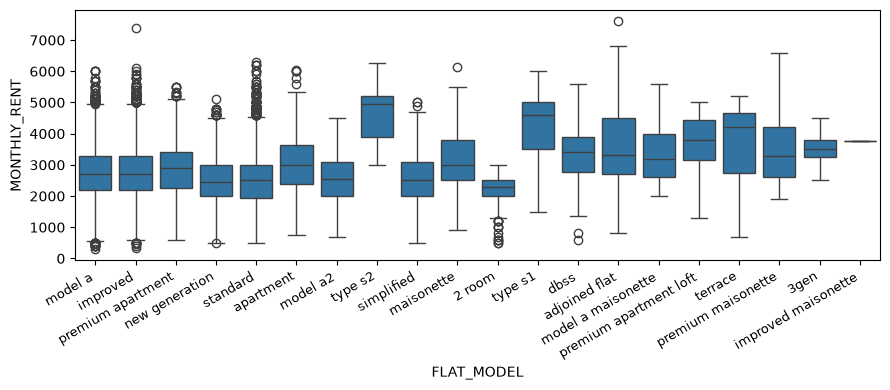

In [42]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=train, x="FLAT_MODEL", y="MONTHLY_RENT")
plt.xticks(rotation=30, ha="right", fontsize=9)
plt.tight_layout()

7. FLOOR_AREA_SQM: Floor area in square meter (e.g., 104.0, 74.0, 136.0). As we saw earlier, this increases with number of rooms. There are no very weird outliers, because the small area points to a 1-room flat and large one means executive flat.

<Axes: xlabel='FLOOR_AREA_SQM', ylabel='MONTHLY_RENT'>

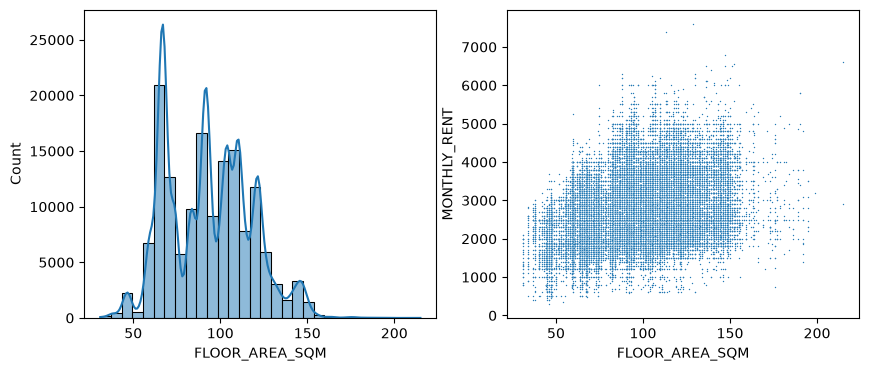

In [47]:
floor_area = train["FLOOR_AREA_SQM"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(data=floor_area, bins=30, kde=True, ax=axes[0])
sns.scatterplot(data=train, x="FLOOR_AREA_SQM", y="MONTHLY_RENT", s=1, ax=axes[1])

8. FURNISHED: Whether the flat is furnished or not. NOTE: All flats are furnished, so we can safely remove this feature from prediction.

<Axes: xlabel='count', ylabel='FURNISHED'>

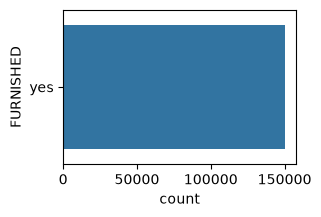

In [49]:
plt.figure(figsize=(3, 2))
sns.countplot(data=train["FURNISHED"])

9. LEASE_COMMENCE_DATE: Year the lease for flat commenced (e.g., 1984, 1985, 1986). This is a weak indicator by itself, but may be strong combined with others.

<Axes: xlabel='LEASE_COMMENCE_DATE', ylabel='MONTHLY_RENT'>

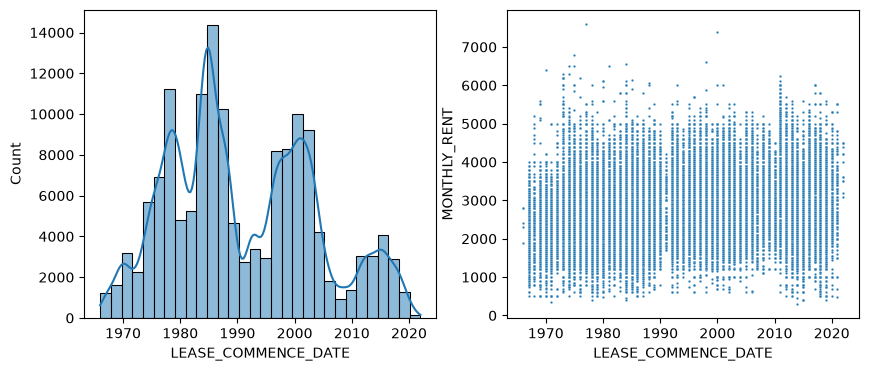

In [51]:
lease_date = train["LEASE_COMMENCE_DATE"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(data=lease_date, bins=30, kde=True, ax=axes[0])
sns.scatterplot(data=train, x="LEASE_COMMENCE_DATE", y="MONTHLY_RENT", s=3, ax=axes[1])

10. FEE: additional upfront fee of rental agreement (e.g., 200, 300, 400). Always 0 for both train and test data, we can safely remove it.

<Axes: xlabel='FEE', ylabel='Count'>

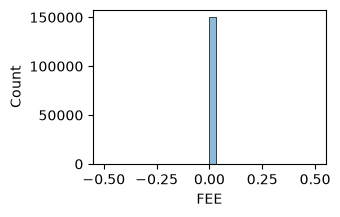

In [53]:
plt.figure(figsize=(3, 2))
sns.histplot(data=train["FEE"], bins=30, kde=True)

11. MONTHLY_RENT: Rental rate SGD (e.g., 2350, 4000, 3200)

<Axes: xlabel='MONTHLY_RENT', ylabel='Count'>

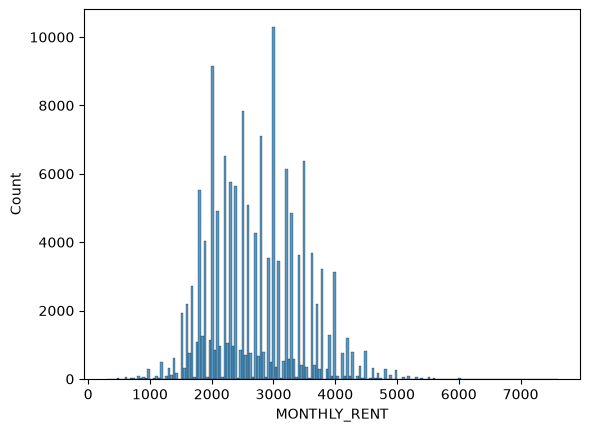

In [59]:
sns.histplot(data=train, x="MONTHLY_RENT")

General pattern: There are certain flats, with each kind of feature, having significantly high rent than others. We can see these very clearly in the boxplots of feature v/s target. 